# Wastewater units, one at a time: how each works and how it is checked

One section per wastewater unit: `ASM1Reactor`, `TakacsSettler`, `ActivatedSludgePlant`, `AnaerobicDigester`. Each is checked against a published steady state:

| Unit | Checked against |
|---|---|
| `ASM1Reactor` | BSM1 report (Alex et al. 2008), Table 6: feed the printed state of one reactor, compare with the next |
| `TakacsSettler` | BSM1 report, Table 7: feed the printed last-reactor state, compare the ten layers |
| `ActivatedSludgePlant` | BSM1 report, Tables 6-7 (the whole plant); WaterTAP's BSM1 example |
| `AnaerobicDigester` | Rosen & Jeppsson (2006), Section 7, a 13-digit verification case; WaterTAP's ADM1 example |

Plant-level studies (aeration energy, washout) are notebooks 75 and 76.

In [1]:
import json
from pathlib import Path
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import difflow_water as dw
from difflow_water.wastewater import STATES, state_to_stream, suspended_solids
from difflow_water.wastewater.adm1 import STATES as ADM1_STATES, ADM1Params, adm1_test_influent, anaerobic_digester

ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
BENCH = ROOT / "benchmarks"
tab = json.loads((BENCH / "bsm1" / "report_tables.json").read_text())
Z_report = np.array([[tab["reactors"][s][k] for s in STATES] for k in range(5)])   # 5 x 13, printed digits
Q_reactors = 92230.0                                                             # m3/d, Table 6

## 1. `ASM1Reactor`: one activated-sludge tank

ASM1's eight processes (heterotrophic aerobic and anoxic growth, autotrophic nitrification, decay, ammonification, hydrolysis) in a completely mixed tank, at steady state. Aeration is set by `KLa` (or a dissolved-oxygen setpoint). How the tank responds to aeration, at the BSM1 last reactor's inlet:

In [2]:
inlet = state_to_stream(Q_reactors, jnp.asarray(Z_report[3]))     # BSM1 reactor 4, as printed
o = STATES.index
for kla in (0.0, 24.0, 84.0, 240.0, 480.0):
    _, i = dw.ASM1Reactor(dw.ASM1ReactorParams(volume=1333.0, KLa=kla))(inlet)
    Z = i["Z"]
    print(f"KLa {kla:5.0f} 1/d: S_O {float(Z[o('S_O')]):5.2f}, S_NH {float(Z[o('S_NH')]):5.2f}, S_NO {float(Z[o('S_NO')]):5.2f} g/m3; "
          f"aeration {float(i['aeration']) / 1e3:6.0f} kg O2/d")

KLa     0 1/d: S_O  0.04, S_NH  3.04, S_NO  8.27 g/m3; aeration      0 kg O2/d
KLa    24 1/d: S_O  0.11, S_NH  2.65, S_NO  8.93 g/m3; aeration    253 kg O2/d
KLa    84 1/d: S_O  0.49, S_NH  1.73, S_NO 10.42 g/m3; aeration    841 kg O2/d
KLa   240 1/d: S_O  3.42, S_NH  1.14, S_NO 11.37 g/m3; aeration   1465 kg O2/d
KLa   480 1/d: S_O  5.38, S_NH  1.09, S_NO 11.44 g/m3; aeration   1674 kg O2/d


**Check against the BSM1 report.** In the open-loop steady state (Table 6) reactor 5 (1333 m3, `KLa = 84 1/d`) is fed by reactor 4, and reactor 2 (1000 m3, anoxic) by reactor 1, all at 92,230 m3/d. Feeding the unit the printed state of the upstream reactor must give the printed state of the downstream one, to the precision the inlet is printed at (3-4 digits; small states such as oxygen and nitrate in an anoxic tank are sensitive to it).

In [3]:
def compare(k_in, V, kla):
    _, i = dw.ASM1Reactor(dw.ASM1ReactorParams(volume=V, KLa=kla))(state_to_stream(Q_reactors, jnp.asarray(Z_report[k_in])))
    print(f"reactor {k_in + 2} from the printed reactor {k_in + 1}:")
    print(f"  {'state':6s} {'report':>10s} {'unit':>10s} {'rel. diff':>10s}")
    for s in STATES:
        w, d = Z_report[k_in + 1][o(s)], float(i["Z"][o(s)])
        print(f"  {s:6s} {w:10.4g} {d:10.4g} {(d - w) / w:+10.1e}")
compare(3, 1333.0, 84.0)
compare(0, 1000.0, 0.0)

reactor 5 from the printed reactor 4:
  state      report       unit  rel. diff
  S_I            30         30   +0.0e+00
  S_S         0.889     0.8896   +7.2e-04
  X_I          1149       1149   +0.0e+00
  X_S          49.3      49.31   +2.6e-04
  X_BH         2559       2559   +6.3e-05
  X_BA          150      150.3   +1.8e-03
  X_P           452      451.9   -2.3e-04
  S_O         0.491      0.489   -4.1e-03
  S_NO         10.4      10.42   +1.7e-03
  S_NH         1.73      1.734   +2.2e-03
  S_ND        0.688     0.6884   +5.8e-04
  X_ND         3.53      3.528   -5.4e-04
  S_ALK        4.13      4.122   -2.0e-03
reactor 2 from the printed reactor 1:
  state      report       unit  rel. diff
  S_I            30         30   +0.0e+00
  S_S          1.46      1.458   -1.1e-03
  X_I          1149       1149   +0.0e+00
  X_S          76.4      76.36   -5.8e-04
  X_BH         2553       2554   +2.4e-04
  X_BA          148      147.9   -5.4e-04
  X_P           450      449.7   -7.3e-04


Both downstream reactors come back within 0.4 % on every state, most within 0.1 %. The largest differences are in dissolved oxygen (0.489 against 0.491 g/m3 in reactor 5) and the autotrophs and alkalinity (0.2 %): one or two units in the last printed digit, the size of the error the 3-4-digit printed inlet carries in (the whole plant, solved without printed intermediate states, matches the same table to 0.3 %, section 3).

## 2. `TakacsSettler`: the secondary clarifier

Ten non-reactive layers; solids settle at the Takacs double-exponential velocity, limited between layers by the smaller flux, with a threshold for the clarification zone. Feed it the BSM1 last reactor and the profile shows the sludge blanket at the bottom and the clear zone above the feed layer (layer 6):

layer   report    unit    rel. diff
    1     6394     6393  -1.1e-04
    2      356      356  +1.3e-04
    3      356      356  +1.3e-04
    4      356      356  +1.3e-04
    5      356      356  +1.3e-04
    6      356      356  +1.3e-04
    7       69    68.97  -3.6e-04
    8     29.5    29.54  +1.3e-03
    9     18.1    18.11  +6.9e-04
   10     12.5     12.5  -2.9e-04


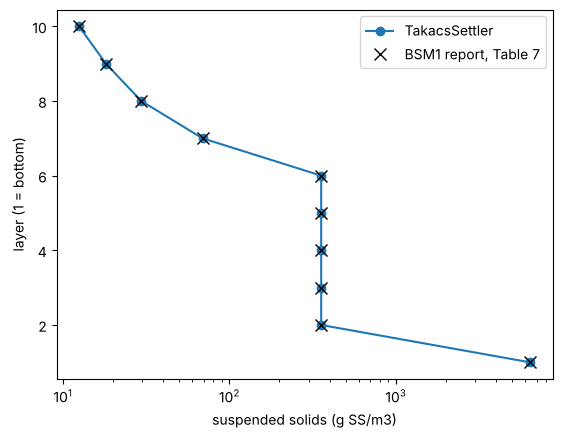

In [4]:
Q_feed = Q_reactors - 55338.0                                           # settler feed = reactor outflow - internal recycle
feed = state_to_stream(Q_feed, jnp.asarray(Z_report[4]))
eff, und, info = dw.TakacsSettler(dw.TakacsSettlerParams(Q_underflow=18446.0 + 385.0))(feed)
X = np.asarray(info["solids"])
report7 = np.array(tab["settler_solids_bottom_first"])
plt.semilogx(X, np.arange(1, 11), "o-", label="TakacsSettler")
plt.semilogx(report7, np.arange(1, 11), "kx", ms=9, label="BSM1 report, Table 7")
plt.xlabel("suspended solids (g SS/m3)"); plt.ylabel("layer (1 = bottom)"); plt.legend()
print("layer   report    unit    rel. diff")
for m in range(10):
    print(f"{m + 1:5d} {report7[m]:8.4g} {X[m]:8.4g} {(X[m] - report7[m]) / report7[m]:+9.1e}")

The settler alone, fed with the printed reactor 5 state, reproduces Table 7 within 0.13 %, to the table's digits. Underflow-rate sensitivity, the design handle:

In [5]:
for Qu in (12000.0, 18831.0, 30000.0):
    _, _, i = dw.TakacsSettler(dw.TakacsSettlerParams(Q_underflow=Qu))(feed)
    print(f"underflow {Qu:7.0f} m3/d: bottom {float(i['TSS_underflow']):6.0f}, effluent {float(i['TSS_effluent']):5.1f} g SS/m3")

underflow   12000 m3/d: bottom  10020, effluent  15.1 g SS/m3


underflow   18831 m3/d: bottom   6393, effluent  12.5 g SS/m3


underflow   30000 m3/d: bottom   4019, effluent   8.5 g SS/m3


## 3. `ActivatedSludgePlant`: BSM1 as one block

The two units above, five reactors and the settler, with the internal and sludge recycles, solved as one equation set (notebook 75 has the plant studies).

In [6]:
eff, waste, info = dw.ActivatedSludgePlant(dw.ActivatedSludgePlantParams())(dw.bsm1_influent())
worst = max(abs(float(info["reactors"][k][o(s)]) / Z_report[k][o(s)] - 1) for k in range(5) for s in STATES)
worst7 = np.max(np.abs(np.asarray(info["settler_solids"]) / report7 - 1))
print(f"largest relative difference from Table 6 (5 reactors x 13 states): {worst:.1e}; from Table 7: {worst7:.1e}")
print(f"sludge age {float(info['sludge_age']):.2f} d (the report: 'about 9 days')")
print("WaterTAP's BSM1 example (split clarifier): within 1.3e-7, see benchmarks/watertap/compare_bsm1.py")

largest relative difference from Table 6 (5 reactors x 13 states): 3.2e-03; from Table 7: 1.4e-03
sludge age 9.14 d (the report: 'about 9 days')
WaterTAP's BSM1 example (split clarifier): within 1.3e-7, see benchmarks/watertap/compare_bsm1.py


## 4. `AnaerobicDigester`: ADM1

ADM1 as implemented for BSM2: disintegration and hydrolysis of solids, acidogenesis, acetogenesis and methanogenesis (19 processes), the acid-base chemistry that sets the pH, and the gas phase. The digester's pH and gas against its operating temperature (only the physico-chemical constants follow temperature; the rates are the report's 35 C values):

In [7]:
for T in (303.15, 308.15, 313.15):
    r = anaerobic_digester(adm1_test_influent(), ADM1Params(T_op=T))
    print(f"{T - 273.15:4.0f} C: pH {float(r['pH']):.3f}, methane {float(r['gas_fraction_ch4']) * 100:.1f} % of {float(r['q_gas']):.0f} m3/d")

  30 C: pH 7.440, methane 62.0 % of 2723 m3/d


  35 C: pH 7.467, methane 60.9 % of 2808 m3/d


  40 C: pH 7.484, methane 59.4 % of 2898 m3/d


**Check against Rosen & Jeppsson (2006), Section 7.** Their verification case (170 m3/d, 35 C) is printed to 13 digits; the unit is run with the gas-flow form that reproduces it (see the docs: the report's text describes a compensated gas flow, its numbers need the uncompensated one).

In [8]:
ref = json.loads((BENCH / "adm1" / "report_steady_state.json").read_text())
r = anaerobic_digester(adm1_test_influent(), ADM1Params(gas_flow="uncompensated"))
devs = {s: float(r["S"][ADM1_STATES.index(s)]) / v - 1 for s, v in ref["states"].items()}
w = max(devs, key=lambda k: abs(devs[k]))
print(f"24 states: largest relative difference {abs(devs[w]):.1e} ({w})")
print(f"pH {float(r['pH']):.10f}  (report {ref['other']['pH']})")
for k, idx in [("S_gas_h2", 0), ("S_gas_ch4", 1), ("S_gas_co2", 2)]:
    print(f"{k:10s} {float(r['G'][idx]):.10g}  (report {ref['other'][k]})")
print("WaterTAP's ADM1 example: within 2.5e-4, see benchmarks/watertap/compare_adm1.py")

24 states: largest relative difference 1.7e-07 (S_h2)
pH 7.4655377699  (report 7.4655377698929)
S_gas_h2   1.02410356e-05  (report 1.02410356e-05)
S_gas_ch4  1.62560721  (report 1.6256072099814)
S_gas_co2  0.01415053468  (report 0.0141505346784)
WaterTAP's ADM1 example: within 2.5e-4, see benchmarks/watertap/compare_adm1.py


## Summary

| Unit | Published check |
|---|---|
| `ASM1Reactor` | BSM1 Table 6, reactor 5 from reactor 4 and reactor 2 from reactor 1, within 0.4 % (the printed inlet's precision) |
| `TakacsSettler` | BSM1 Table 7, the ten layers from the printed reactor 5, within 0.13 % |
| `ActivatedSludgePlant` | BSM1 Tables 6-7 within 0.3 %, the printed digits; WaterTAP 1.3e-7 |
| `AnaerobicDigester` | Rosen & Jeppsson's 13-digit case to 1.7e-7; WaterTAP 2.5e-4 |